# U04 — Three generated-history bands: suppression and boost

**60 rewrites: the same first 10 cases of the frozen U03 cohort × six arms.**
Start from **Llama + WITH_PREV + Unique primary + SAMPLE_T10 secondary + rewind + DP**.
The final End arm uses **λ=1.25**. All unmentioned multipliers are 1.

| Arm | Generated-history distance from the predicted next token | λ |
|---|---|---:|
| FRONT_075 | 1–63 model tokens (`<64`) | 0.75 |
| MID_075 | 64–128 model tokens (inclusive) | 0.75 |
| END_075 | 129+ model tokens (`>128`) | 0.75 |
| FRONT_125 | 1–63 model tokens | 1.25 |
| MID_125 | 64–128 model tokens | 1.25 |
| END_125 | 129+ model tokens | 1.25 |

“Front” is recent self-history, not the beginning of the document. These are
**token-lag bands**, not paragraph indices, word ranges, or a schedule over output length.
An unavailable band has no effect yet. At each attention layer/head we add
`log(λ)` to the selected generated-key scores before softmax, equivalently
`a'_ij = λ_band(i,j) a_ij / sum_k λ_band(i,k) a_ik` for fixed Q/K scores.
The entire task, original RAID AI answer, DP instruction, and chat-format prefix
have multiplier 1. Attention renormalization can still change their *normalized*
mass. Biases apply at every causal query position; past hidden states therefore
carry the intervention too. No tokens are deleted and positions are unchanged.

This is **attention-mass reweighting**, not U01's full/short probability mixture
and not multiplying raw QK scores by λ. It supports both suppression and boost
without additional model branches. No claim is made that λ=1.25 causes exactly
25% more final information use. The mechanism uses Hugging Face's
[custom 4D additive masks](https://huggingface.co/docs/transformers/main/en/attention_interface#pass-a-custom-4d-attention-mask).

## Run and resume

1. Put this notebook in `reproduction/experiments/` beside U02 and U03.
2. Run Sections 0–4 once. These load definitions, validate saved benchmarks, and
   run short mask checks; **no new rewrite** is generated there.
3. Run **one arm cell at a time** in Section 5 (ten cases each). Run All would
   execute all six arms sequentially. No generation is parallelized.
4. Each completed EOS **or token-capped** text is atomically saved immediately.
   After interruption, rerun setup and the interrupted arm cell: completed cases
   are skipped. Only the unfinished case restarts from its original seed.
   Live progress is diagnostic, not a resumable mid-text RNG/controller snapshot.
5. Section 6 scores only saved outputs and plots each completed arm against the
   **same ten** U03 DP / OG / HUMAN benchmarks. It can run after any full arm.

Output: `results/causal/U04_context_range_sweep_v1/`. Per-run JSON files are
authoritative; tables are rebuilt from them on resume. Checksums and a frozen
contract prevent mixing settings or changed inputs. Use a new namespace for a
different experiment. Generation never consumes subject-specific human text;
only the existing aggregate Unique bands are retained. HUMAN benchmark scores
are imported from U03, not passed to the generator. No information pool is used.

## 0. Load the frozen U02 controller without executing its experiments

In [1]:
# ============================================================
# 0. Load the exact frozen U02 machinery as a library
# ============================================================

# Rerunning setup releases this notebook's prior generator/scorer references.
import gc
for _old in ("model", "u04_scorer", "u04_scorer_tok"):
    globals().pop(_old, None)
gc.collect()
from pathlib import Path
import ast, copy, gc, hashlib, json, math, re, heapq
from collections import Counter

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForCausalLM
from tqdm.auto import tqdm
from IPython.display import display

ROOT_CANDIDATES = [
    Path.cwd().resolve(),
    *Path.cwd().resolve().parents,
    Path.home() / "Downloads" / "TemporalContextResearch" / "reproduction",
]
ROOT = next((p for p in ROOT_CANDIDATES if (p / "experiments/U02_hybrid_unique_sampling.ipynb").exists()), None)
assert ROOT is not None, "Could not locate TemporalContextResearch/reproduction."

U02_NB = ROOT / "experiments/U02_hybrid_unique_sampling.ipynb"
u02_nb = json.loads(U02_NB.read_text())


def get_u02_code(marker):
    hits = []
    for cell in u02_nb["cells"]:
        if cell.get("cell_type") != "code":
            continue
        src = "".join(cell.get("source", []))
        # The final U02 diagnostic cell quotes many earlier markers as strings.
        # Exclude that probe so we recover the actual frozen definition cell.
        if marker in src and "# U03 PROBE 0 — Referent-oriented prompt diagnostic" not in src:
            hits.append(src)
    assert len(hits) == 1, (marker, len(hits))
    return hits[0]


SETUP_MARKERS = [
    'MODEL_ID = "meta-llama/Llama-3.2-3B-Instruct"',
    "# Reconstruct the exact cohort and Unique contracts used by U01b.",
    "# Load the canonical Unique controller from C02w2 without executing generation cells.",
    "def build_messages(prompt, previous_ai):",
    "# U02 freezes the U01b FULL arm.",
    "# Recover ONLY the JointTemporalBackend class definition",
    "class HybridBackend(JointTemporalBackend):",
]

# Keep the located repository root; do not execute U02's cwd reassignment.
for marker in SETUP_MARKERS:
    print("Executing U02 definition:", marker[:72])
    source = get_u02_code(marker)
    if marker.startswith('MODEL_ID'):
        source = source[source.index('U01B_NB ='):]
    if marker == "def build_messages(prompt, previous_ai):":
        source = source.replace('low_cpu_mem_usage=True,',
                                'low_cpu_mem_usage=True, attn_implementation="sdpa",')
    if marker == "# Recover ONLY the JointTemporalBackend class definition":
        source = source.split('# One REAL FULL-history forward pass.')[0]
    exec(compile(source, str(U02_NB), "exec"), globals())

# Load U02's final coherence/recovery machinery, but do not reload the generator.
fs_src = get_u02_code("# U02 — FINAL full system, generated FROM SCRATCH")
reload_start = fs_src.index(
    "# ------------------------------------------------------------\n"
    "# 2. Reload generator."
)
reload_end = fs_src.index(
    "# ------------------------------------------------------------\n"
    "# 3. Deterministic fresh-run seeds"
)
fs_src = (
    fs_src[:reload_start]
    + "# Generator already loaded by the exact U02 setup cell.\n\n"
    + fs_src[reload_end:]
)
# Import recovery definitions without executing U02's contract-writing block.
fs_src = fs_src[:fs_src.index("# 11. Contract")]
exec(compile(fs_src, str(U02_NB), "exec"), globals())


# Preserve the frozen U02 likelihood guard.
globals()["search_word"] = make_search(UNIQUE_RATIO_FLOOR)
# Verify exact AI row rather than relying on U02's raw-ID fallback mapping.
for r in cohort.itertuples(index=False):
    hit=paired.loc[paired.source_id.astype(str).eq(str(r.source_id)) & paired.label.eq(1)]
    assert len(hit)==1, f"{r.case_id}: ambiguous/missing exact AI source"
    assert str(hit.iloc[0].text)==str(r.previous_ai), f"{r.case_id}: WITH_PREV mismatch"
print("All WITH_PREV inputs match exact paired-corpus AI rows.")
# No paired human prose is needed in the generation namespace.
paired = paired.loc[paired.label.eq(1)].copy()
for _map_name in ("exact", "rawmap"):
    globals().pop(_map_name, None)
assert model.config._attn_implementation == "sdpa", model.config._attn_implementation
print("U04 generator attention: SDPA; all other U02 controller definitions retained.")

/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Executing U02 definition: MODEL_ID = "meta-llama/Llama-3.2-3B-Instruct"
ROOT: ..
Output: ../results/causal/U02_hybrid_unique_sampling
Device: cuda
Unique guard floor: 0.05
Secondary sampling: T=1.0, top_p=1.0
Executing U02 definition: # Reconstruct the exact cohort and Unique contracts used by U01b.
Cases: 20
Unique contract: ../results/causal/C02r_discovery_gated_punctuation/frozen_contract.json
Theta schedules: {'increase': {'minimum': 0.005, 'maximum': 0.1, 'slope': 4.0, 'midpoint': 1.0}, 'decrease': {'minimum': 0.005, 'maximum': 0.1, 'slope': 4.0, 'midpoint': 1.0}}
Max completed candidates: 500


,case_id,source_id,domain
0,gate_0090,ai__raid:e3945a96-7048-41d9-9e86-a84e87818986,abstracts
1,gate_0070,ai__raid:7a3b622e-1e88-48ce-98e0-2f87da5c573c,books
2,gate_0017,ai__raid:b4b807b1-fbfa-43d8-9fc3-61bd36b078ef,news
3,gate_0085,ai__raid:fa8bd0e4-3134-4d4d-83e4-4749c0bf6462,recipes
4,gate_0038,ai__raid:bf3df034-9724-4840-86cb-33eb1489b717,reddit
5,gate_0039,ai__raid:8760103e-729a-4bab-b799-5775ac2468b1,wiki
6,gate_0069,ai__raid:c7b5fc38-2bbb-4e44-bba7-dc8ac8eae773,abstracts
7,gate_0035,ai__raid:e0c2314e-b8d9-422e-af55-1498f8c4dce9,books
8,gate_0003,ai__raid:2abdd1df-30c9-4db4-bc75-08ae57b9ec93,news
9,gate_0025,ai__raid:dab3ef7f-6a54-49f9-9367-e907f0618c82,recipes


Executing U02 definition: # Load the canonical Unique controller from C02w2 without executing gene
Canonical Unique engine loaded.
Search budget: {'version': 'word_search_budget_pilot_v1', 'max_expanded': 1000, 'max_frontier': 10000}
Executing U02 definition: def build_messages(prompt, previous_ai):


Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████████| 254/254 [00:00<00:00, 482.24it/s]


Loaded: meta-llama/Llama-3.2-3B-Instruct
EOS: {128008, 128001, 128009}
CUDA free after load: 0.56/7.62 GiB
Executing U02 definition: # U02 freezes the U01b FULL arm.
FULL temporal-history multiplier fixed at 1.0 for all positions.
Executing U02 definition: # Recover ONLY the JointTemporalBackend class definition
Executing U02 definition: class HybridBackend(JointTemporalBackend):
Hybrid controller defined.
All WITH_PREV inputs match exact paired-corpus AI rows.
U04 generator attention: SDPA; all other U02 controller definitions retained.


## 1. Freeze the six arms, ten cases, prompts, and benchmark provenance

In [2]:
import os, time, platform, tempfile, contextlib, fcntl, transformers
from collections import OrderedDict

U04_NAMESPACE = "U04_context_range_sweep_v1"
U04_OUT = ROOT / "results/causal" / U04_NAMESPACE
U04_RUNS = U04_OUT / "runs"
U04_PROGRESS = U04_OUT / "progress"
for directory in (U04_OUT, U04_RUNS, U04_PROGRESS):
    directory.mkdir(parents=True, exist_ok=True)

FS_MAX_REWINDS = 10
RUN_CASES = cohort.case_id.astype(str).head(10).tolist()
assert len(RUN_CASES) == len(set(RUN_CASES)) == 10
run_cohort = cohort.set_index("case_id").loc[RUN_CASES].reset_index()
ARMS = {
    "FRONT_075": (0.75, 1.0, 1.0), "MID_075": (1.0, 0.75, 1.0),
    "END_075": (1.0, 1.0, 0.75), "FRONT_125": (1.25, 1.0, 1.0),
    "MID_125": (1.0, 1.25, 1.0), "END_125": (1.0, 1.0, 1.25),
}
METRICS = ["P_S_gt_4", "P_S_gt_6", "P_S_gt_8"]
HEARTBEAT_SECONDS = 30
U03_OUT = ROOT / "results/causal/U03_INFO_POOL_ALL20_GENERAL_v2"
U03_COMPARE = U03_OUT / "comparison_reused_u02"
U03_NB = ROOT / "experiments/U03_information_pool_all20.ipynb"
SELF_NB = ROOT / "experiments/U04_context_range_sweep.ipynb"

def sha_text(value):
    return hashlib.sha256(str(value).encode("utf-8")).hexdigest()

def jsonable(value):
    if isinstance(value, dict): return {str(k):jsonable(v) for k,v in value.items()}
    if isinstance(value, (list, tuple)): return [jsonable(x) for x in value]
    if isinstance(value, np.generic): return jsonable(value.item())
    if isinstance(value, float) and not math.isfinite(value): return None
    if isinstance(value, Path): return str(value)
    return value

def fingerprint(value):
    return sha_text(json.dumps(jsonable(value), sort_keys=True, ensure_ascii=False))

def atomic_json(path, value):
    """Write a complete record, fsync it, then atomically rename on the same disk."""
    path = Path(path)
    fd, temporary = tempfile.mkstemp(prefix=path.name+".", suffix=".tmp", dir=path.parent)
    try:
        with os.fdopen(fd, "w", encoding="utf-8") as handle:
            json.dump(jsonable(value), handle, ensure_ascii=False, indent=2, allow_nan=False)
            handle.flush(); os.fsync(handle.fileno())
        os.replace(temporary, path)
        directory_fd = os.open(str(path.parent), os.O_RDONLY)
        try: os.fsync(directory_fd)
        finally: os.close(directory_fd)
    finally:
        if os.path.exists(temporary): os.unlink(temporary)

@contextlib.contextmanager
def generation_lock():
    # An OS lock is released automatically if the kernel dies.
    with (U04_OUT / "generation.lock").open("a+") as handle:
        try: fcntl.flock(handle, fcntl.LOCK_EX | fcntl.LOCK_NB)
        except BlockingIOError:
            raise RuntimeError("Another kernel is generating this U04 experiment.")
        try: yield
        finally: fcntl.flock(handle, fcntl.LOCK_UN)

def notebook_code_hash(path):
    nb = json.loads(Path(path).read_text())
    return fingerprint(["".join(c.get("source", [])) for c in nb["cells"]
                        if c.get("cell_type") == "code"])

# Read only the literal accepted DP instruction, without executing U03's runs.
u03_nb = json.loads(U03_NB.read_text())
prompt_literals = []
for cell in u03_nb["cells"]:
    if cell.get("cell_type") != "code": continue
    for node in ast.parse("".join(cell.get("source", []))).body:
        if isinstance(node, ast.Assign) and any(
            isinstance(t, ast.Name) and t.id == "REFERENT_INSTRUCTION" for t in node.targets
        ):
            prompt_literals.append(ast.literal_eval(node.value))
assert len(prompt_literals) == 1, "Expected one literal U03 DP instruction."
REFERENT_INSTRUCTION = prompt_literals[0]
_base_messages = build_messages

def dp_messages(task, previous_ai):
    messages = copy.deepcopy(_base_messages(str(task), str(previous_ai)))
    messages[0]["content"] += "\n\n" + REFERENT_INSTRUCTION
    return messages

def encode_dp(row):
    rendered = tok.apply_chat_template(dp_messages(row.prompt, row.previous_ai),
                                      tokenize=False, add_generation_prompt=True)
    return tok(rendered, add_special_tokens=False)["input_ids"]

score_path = U03_COMPARE / "five_group_scores.csv"
panel_path = U03_COMPARE / "generations.parquet"
assert score_path.exists() and panel_path.exists(), "Run/save the U03 comparison first."
u03_scores = pd.read_csv(score_path)
u03_panel = pd.read_parquet(panel_path)
benchmark_scores = u03_scores.loc[
    u03_scores.case_id.astype(str).isin(RUN_CASES)
    & u03_scores.arm.isin(["HUMAN", "OG", "DIRECT_PROMPT"])
].copy()
assert not benchmark_scores.duplicated(["case_id", "arm"]).any()
assert len(benchmark_scores) == 30 and benchmark_scores[METRICS].notna().all().all()
assert benchmark_scores.groupby("case_id").arm.nunique().eq(3).all()
assert np.isfinite(benchmark_scores[METRICS].to_numpy()).all()
assert ((benchmark_scores[METRICS] >= 0) & (benchmark_scores[METRICS] <= 1)).all().all()

benchmark_provenance = []
benchmark_texts = {}  # AI text only; never supplied to generation except OG via WITH_PREV.
for row in run_cohort.itertuples(index=False):
    cid = str(row.case_id)
    hit = u03_panel.loc[u03_panel.case_id.astype(str).eq(cid)
                       & u03_panel.arm.eq("DIRECT_PROMPT") & u03_panel.replicate.eq(0)]
    assert len(hit) == 1, f"Missing/duplicate U03 DP: {cid}"
    saved_text = str(hit.iloc[0].generated_text)
    audits = []
    for path in (U03_OUT / "states").glob(f"{cid}__DIRECT_PROMPT__s0__*.json"):
        item = json.loads(path.read_text())
        spec, summary = item["spec"], item["summary"]
        if (summary.get("generated_text") == saved_text
            and spec.get("previous_ai_sha") == sha_text(row.previous_ai)
            and spec.get("task_sha") == sha_text(row.prompt)
            and spec.get("messages") == dp_messages(row.prompt, row.previous_ai)
            and int(spec.get("seed", -1)) == fs_case_seed(cid)
            and summary.get("stop_reason") in {"eos", "truncated"}):
            assert summary["text_sha"] == sha_text(saved_text)
            audits.append((path, item))
    assert len(audits) == 1, f"{cid}: expected one matching U03 DP audit, got {len(audits)}"
    audit_path, audit = audits[0]
    benchmark_texts[cid] = {"DIRECT_PROMPT":saved_text, "OG":str(row.previous_ai)}
    benchmark_provenance.append(dict(case_id=cid, source_id=str(row.source_id),
        original_ai_sha=sha_text(row.previous_ai), dp_text_sha=sha_text(saved_text),
        dp_stop_reason=audit["summary"]["stop_reason"], audit=str(audit_path)))

assert SELF_NB.exists(), f"Save this notebook as {SELF_NB} before running."
CONTRACT = jsonable(dict(
    version=U04_NAMESPACE, cases=RUN_CASES, arms=ARMS, replicate=0,
    model_id=MODEL_ID, model_commit=getattr(model.config, "_commit_hash", None),
    dtype=str(next(model.parameters()).dtype), attention_implementation="sdpa",
    mechanism="causal_log_lambda_generated_key_bias_all_layers_v1",
    bands="lag_1_to_63__64_to_128__129_plus", prompt_weight=1.0,
    context="WITH_PREV_original_RAID_AI_plus_DP", referent_prompt=REFERENT_INSTRUCTION,
    token_cap=FS_MAX_NEW_TOKENS, rewind_cap=FS_MAX_REWINDS,
    entropy_window=FS_H_WINDOW, entropy_danger=FS_H_DANGER,
    entropy_persistence=FS_H_PERSISTENCE, rewind_backoff=FS_REWIND_BACKOFF_TOKENS,
    sample_temperature=SAMPLE_TEMPERATURE, sample_top_p=SAMPLE_TOP_P,
    unique_ratio_floor=UNIQUE_RATIO_FLOOR, theta_schedules=UNIQUE_THETA_SCHEDULES,
    fallback="greedy_no_Unique_with_same_history_bias",
    rng_policy="same_U02_case_seed_per_arm; not_rewound_on_coherence_recovery",
    python=platform.python_version(), torch=torch.__version__, transformers=transformers.__version__,
    controller_sources={str(p.relative_to(ROOT)):notebook_code_hash(p)
                        for p in (U02_NB, U01B_NB, UNIQUE_NB, SELF_NB)},
    case_inputs=[dict(case_id=str(r.case_id), source_id=str(r.source_id), domain=str(r.domain),
                     task_sha=sha_text(r.prompt), previous_ai_sha=sha_text(r.previous_ai),
                     uq_contract_sha=fingerprint(case_contract[str(r.case_id)]))
                 for r in run_cohort.itertuples(index=False)],
    benchmark_rows_sha=fingerprint(benchmark_scores.sort_values(["case_id", "arm"]).to_dict("records")),
    benchmark_provenance=benchmark_provenance,
))
with generation_lock():
    contract_path = U04_OUT / "contract.json"
    if contract_path.exists():
        assert json.loads(contract_path.read_text()) == CONTRACT, (
            "U04 contract changed. Restore original settings or choose a new U04_NAMESPACE. "
            "No cached result was overwritten.")
    else: atomic_json(contract_path, CONTRACT)
CONTRACT_SHA = fingerprint(CONTRACT)
benchmark_scores.to_csv(U04_OUT / "benchmark_scores.csv", index=False)
display(pd.DataFrame(ARMS, index=["front_<64", "mid_64_to_128", "end_>128"]).T)
display(run_cohort[["case_id", "domain"]])
print("Output:", U04_OUT, "| planned rewrites:", len(RUN_CASES)*len(ARMS))
print("Benchmarks: 30 saved scores for these exact 10 cases. No rewrite started.")

,front_<64,mid_64_to_128,end_>128
FRONT_075,0.75,1.00,1.00
MID_075,1.00,0.75,1.00
END_075,1.00,1.00,0.75
FRONT_125,1.25,1.00,1.00
MID_125,1.00,1.25,1.00
END_125,1.00,1.00,1.25


,case_id,domain
0,gate_0090,abstracts
1,gate_0070,books
2,gate_0017,news
3,gate_0085,recipes
4,gate_0038,reddit
5,gate_0039,wiki
6,gate_0069,abstracts
7,gate_0035,books
8,gate_0003,news
9,gate_0025,recipes


Output: ../results/causal/U04_context_range_sweep_v1 | planned rewrites: 60
Benchmarks: 30 saved scores for these exact 10 cases. No rewrite started.


## 2. Causal attention weighting and runtime preflight

In [3]:
def history_bias(prompt_length, generated_length, lambdas, *, dtype, device):
    """A full causal, additive 4D mask. Lag 1 is the last generated input token."""
    assert prompt_length > 0 and generated_length >= 0
    assert len(lambdas) == 3 and all(math.isfinite(x) and x > 0 for x in lambdas)
    n = prompt_length + generated_length
    positions = torch.arange(n, device=device)
    qpos, kpos = positions[:, None], positions[None, :]
    causal = kpos <= qpos
    lag = qpos - kpos + 1
    generated = (kpos >= prompt_length) & causal
    weights = torch.ones((n, n), dtype=torch.float32, device=device)
    for selected, lam in zip((lag < 64, (lag >= 64) & (lag <= 128), lag > 128), lambdas):
        weights.masked_fill_(generated & selected, float(lam))
    bias = weights.log()
    # A per-query constant leaves softmax unchanged. Keep max=0 for older HF versions.
    bias = bias - bias.masked_fill(~causal, float("-inf")).amax(dim=-1, keepdim=True)
    bias.masked_fill_(~causal, float("-inf"))
    return bias.to(dtype=dtype)[None, None]

def history_is_active(generated_length, lambdas):
    return any(float(lam) != 1.0 and generated_length >= first_lag
               for lam,first_lag in zip(lambdas,(1,64,129)))

class U04Backend(FullSystemBackend):
    def __init__(self, input_ids, lambdas, seed, label=""):
        super().__init__(input_ids, "FULL", seed)
        self.lambdas = tuple(lambdas)
        self.label = label
        self._q_cache = OrderedDict()
        self.cache_hits = 0
        self.started = self.last_heartbeat = time.monotonic()

    @torch.inference_mode()
    def _distribution(self, ids):
        ids = tuple(int(x) for x in ids)
        if len(ids) >= MAX_NEW_TOKENS: raise TokenCapReached("Reached the 640-token cap")
        if ids in self._q_cache:
            self.cache_hits += 1
            cached = self._q_cache.pop(ids)
            self._q_cache[ids] = cached
            q = cached.to(device)
        else:
            x = torch.tensor([self.prompt_ids + list(ids)], dtype=torch.long, device=device)
            # Preserve the native path exactly until the selected band exists.
            mask = (history_bias(len(self.prompt_ids), len(ids), self.lambdas,
                                 dtype=next(model.parameters()).dtype, device=device)
                    if history_is_active(len(ids),self.lambdas) else None)
            output = model(input_ids=x, attention_mask=mask, use_cache=False, logits_to_keep=1)
            q = F.softmax(output.logits[0, -1].float(), dim=-1)
            self.forward_calls += 1
            del output, x, mask
            if not torch.isfinite(q).all().item():
                raise IncompleteGeneration("Non-finite U04 distribution")
            # Bounded CPU memoization: identical prefixes recur in Unique search.
            self._q_cache[ids] = q.detach().cpu().clone()
            while len(self._q_cache) > 16: self._q_cache.popitem(last=False)
        valid = q.clone()
        for tid in FORBIDDEN_SPECIAL:
            if 0 <= tid < len(valid): valid[tid] = 0
        mass = valid.sum()
        if not torch.isfinite(mass).item() or float(mass.item()) <= 0:
            raise IncompleteGeneration("No permitted U04 probability mass")
        valid /= mass
        nz = valid > 0
        self.entropy_by_prefix[ids] = float(-(valid[nz]*valid[nz].log()).sum().item())
        now = time.monotonic()
        if self.label and now-self.last_heartbeat >= HEARTBEAT_SECONDS:
            print(f"  {self.label}: evaluating prefix {len(ids)} tokens | "
                  f"{self.forward_calls} forwards | {(now-self.started)/60:.1f} min", flush=True)
            self.last_heartbeat = now
        return q

@torch.inference_mode()
def u04_preflight():
    # Exact boundaries, no prompt-key multiplier, and future-token exclusion.
    for lambdas in ARMS.values():
        mask = history_bias(7, 140, lambdas, dtype=torch.float32, device="cpu")[0, 0]
        assert torch.isneginf(mask.triu(diagonal=1)[torch.triu(torch.ones_like(mask), 1).bool()]).all()
        for lag in (1, 63, 64, 128, 129, 140):
            expected = lambdas[0 if lag < 64 else 1 if lag <= 128 else 2]
            # Ratios cancel the harmless row-constant shift.
            actual = torch.exp(mask[-1, -lag]-mask[-1, 0]).item()
            assert abs(actual-expected) < 1e-6, (lag, actual, expected)
        assert torch.allclose(mask[-1, :7], mask[-1, 0].expand(7))
    for n in (0, 1, 63):
        assert torch.equal(history_bias(3,n,ARMS["MID_075"],dtype=torch.float32,device="cpu"),
                           history_bias(3,n,(1.,1.,1.),dtype=torch.float32,device="cpu"))
    for n in (0, 1, 64, 128):
        assert torch.equal(history_bias(3,n,ARMS["END_125"],dtype=torch.float32,device="cpu"),
                           history_bias(3,n,(1.,1.,1.),dtype=torch.float32,device="cpu"))

    # Verify the installed Llama/Transformers actually consumes the mask.
    row = run_cohort.iloc[0]
    prompt = encode_dp(row)
    history = tok(str(row.previous_ai), add_special_tokens=False)["input_ids"]
    assert history, "Empty original AI text"
    history = (history * (140//len(history)+1))[:140]
    x = torch.tensor([prompt+history], dtype=torch.long, device=device)
    native = F.softmax(model(input_ids=x,use_cache=False,logits_to_keep=1).logits[0,-1].float(),dim=-1)
    backend = U04Backend(prompt,(1.,1.,1.),fs_case_seed(str(row.case_id)))
    neutral = backend._distribution(history)
    neutral_mask = history_bias(len(prompt),len(history),(1.,1.,1.),
                               dtype=next(model.parameters()).dtype,device=device)
    custom_neutral = F.softmax(model(input_ids=x,attention_mask=neutral_mask,use_cache=False,
                                    logits_to_keep=1).logits[0,-1].float(),dim=-1)
    custom_mask_tv = float((native-custom_neutral).abs().sum()/2)
    assert custom_mask_tv < 0.005, f"Neutral 4D mask mismatch: TV={custom_mask_tv}"
    max_abs = float((native-neutral).abs().max())
    total_variation = float((native-neutral).abs().sum()/2)
    assert total_variation < 0.005, (
        f"Neutral custom mask differs too much from native attention: TV={total_variation}. "
        "No generation started; inspect the installed attention backend.")
    records = []
    for arm, lambdas in ARMS.items():
        candidate = U04Backend(prompt,lambdas,fs_case_seed(str(row.case_id)))
        changed = candidate._distribution(history)
        tv = float((changed-neutral).abs().sum()/2)
        assert tv > 1e-8, f"{arm}: mask appears ignored; no generation started."
        records.append(dict(arm=arm,preflight_TV_from_neutral=tv))
        del candidate, changed
    report = dict(neutral_max_abs=max_abs, neutral_TV=total_variation,
                  neutral_custom_mask_TV=custom_mask_tv, arms=records)
    atomic_json(U04_OUT / "attention_preflight.json", report)
    print("Neutral custom-mask vs native TV:", total_variation)
    display(pd.DataFrame(records))
    del native, neutral, custom_neutral, neutral_mask, backend, x
    if device.type == "cuda": torch.cuda.empty_cache()
    return report

PREFLIGHT = u04_preflight()
PREFLIGHT_CONTRACT_SHA = CONTRACT_SHA
print("Mask boundaries and all six arm effects verified. No rewrite started.")

Neutral custom-mask vs native TV: 0.0


,arm,preflight_TV_from_neutral
0,FRONT_075,0.002681
1,MID_075,0.000977
2,END_075,0.000645
3,FRONT_125,0.002011
4,MID_125,0.001032
5,END_125,0.001045


Mask boundaries and all six arm effects verified. No rewrite started.


## 3. Durable per-generation checkpoints and the unchanged Unique/recovery loop

In [4]:
def run_spec(row, arm):
    return dict(contract_sha=CONTRACT_SHA, case_id=str(row.case_id), arm=arm,
                lambdas=list(ARMS[arm]), seed=fs_case_seed(str(row.case_id)), replicate=0,
                task_sha=sha_text(row.prompt), previous_ai_sha=sha_text(row.previous_ai),
                messages=dp_messages(row.prompt,row.previous_ai),
                uq_contract_sha=fingerprint(case_contract[str(row.case_id)]))

def result_path(cid, arm):
    return U04_RUNS / f"{cid}__{arm}.json"

def read_completed(path, spec):
    if not path.exists(): return None
    try: saved = json.loads(path.read_text())
    except (ValueError, OSError) as exc:
        raise RuntimeError(f"Cannot read checkpoint {path}; restore it before rerunning.") from exc
    assert saved["spec"] == spec, f"Checkpoint/input mismatch: {path}"
    row = saved["summary"]
    assert row["stop_reason"] in {"eos", "truncated"}, f"Incomplete result in {path}"
    assert row["text_sha"] == sha_text(row["generated_text"]), f"Changed output: {path}"
    assert saved["record_sha"] == fingerprint({k:v for k,v in saved.items() if k!="record_sha"}), (
        f"Checkpoint checksum mismatch: {path}")
    return row

def save_completed(path, spec, summary, state, events):
    record = jsonable(dict(spec=spec, summary=summary, state=state, rewind_events=events))
    record["record_sha"] = fingerprint(record)
    atomic_json(path, record)

def rebuild_tables():
    rows, statuses = [], []
    for arm in ARMS:
        for src in run_cohort.itertuples(index=False):
            cid = str(src.case_id)
            saved = read_completed(result_path(cid,arm), run_spec(src,arm))
            if saved is not None: rows.append(saved)
            statuses.append(dict(case_id=cid, domain=str(src.domain), arm=arm,
                                 status=saved["stop_reason"] if saved else "pending"))
    frame = pd.DataFrame(rows)
    atomic_json(U04_OUT / "completed_generations.json", rows)
    frame.to_csv(U04_OUT / "completed_generations.csv", index=False)
    status_frame = pd.DataFrame(statuses)
    status_frame.to_csv(U04_OUT / "batch_status.csv", index=False)
    return frame, status_frame

@torch.inference_mode()
def u04_greedy_finish(backend, state, heartbeat):
    # Keep the arm's history weighting during no-Unique fallback.
    ids = list(state["ids"])
    probabilities = list(state.get("probabilities", []))
    while len(ids) < FS_MAX_NEW_TOKENS and not backend.ended(ids):
        token, probability = backend.choices(ids, threshold=None)[0]
        ids.append(int(token)); probabilities.append(float(probability))
        state.update(ids=ids, probabilities=probabilities)
        heartbeat(state)
    text = backend.decode(ids)
    eos = backend.ended(ids)
    state.update(ids=ids, probabilities=probabilities, committed_text=text,
                 words=[w.lower() for w,_,_ in word_spans(text)], mode="normal",
                 finished=eos, status="completed_eos_greedy_fallback" if eos else "truncated_token_cap")
    return state

def generate_case(src, arm):
    global _FS_RUNTIME
    spec = run_spec(src, arm)
    cid = str(src.case_id)
    path = result_path(cid, arm)
    saved = read_completed(path, spec)
    if saved is not None: return saved, True
    c = case_contract[cid]; curve = c["curve"]
    input_ids = encode_dp(src)
    limit = getattr(model.config,"max_position_embeddings",None)
    assert not limit or len(input_ids)+FS_MAX_NEW_TOKENS <= limit
    backend = U04Backend(input_ids, ARMS[arm], spec["seed"], f"{arm} / {cid}")
    state = initial_state(arm)
    runtime = dict(case_id=cid,last_supported_ref=fs_last_supported_reference(curve),
        recovery_until_word=None,epoch_entropy=[],danger_run=0,last_monitored_token_count=0,
        snapshots=[fs_snapshot_state(state)],events=[],alarm_pending=False,rewinds=0,
        discarded_tokens=0,used_greedy_fallback=False,fallback_reason=None)
    started = time.monotonic()
    progress_path = U04_PROGRESS / f"{cid}__{arm}.json"
    last_progress = [0.]
    def heartbeat(current, force=False, status="running"):
        now = time.monotonic()
        if force or now-last_progress[0] >= HEARTBEAT_SECONDS:
            atomic_json(progress_path, dict(spec=spec,status=status,
                committed_tokens=len(current.get("ids",[])),committed_words=len(current.get("words",[])),
                rewinds=runtime["rewinds"],elapsed_seconds=now-started,
                restart_policy="unfinished_case_restarts_from_seed"))
            last_progress[0] = now
    original_runtime = _FS_RUNTIME
    old_mode, old_theta = adaptive_mode, adaptive_theta
    _FS_RUNTIME = runtime
    globals()["adaptive_mode"], globals()["adaptive_theta"] = fs_adaptive_mode, fs_adaptive_theta
    monitor = fs_make_checkpoint(backend,runtime)
    def checkpoint(current):
        monitor(current)
        heartbeat(current)
    try:
        heartbeat(state, force=True)
        while True:
            try:
                run_feedback_hybrid(backend,state,curve,int(c["warmup_words"]),
                                    UNIQUE_THETA_SCHEDULES,checkpoint=checkpoint)
                break
            except FSCoherenceCollapse as collapse:
                runtime["alarm_pending"] = False
                fs_restore_state(state,collapse.target_snapshot)
                runtime["discarded_tokens"] += int(collapse.event["tokens_removed"])
                if runtime["rewinds"] >= FS_MAX_REWINDS:
                    runtime["used_greedy_fallback"] = True
                    runtime["fallback_reason"] = "coherence_rewind_limit"
                    u04_greedy_finish(backend,state,heartbeat)
                    break
                runtime["rewinds"] += 1
                runtime["recovery_until_word"] = max(int(collapse.event["alarm_word"]),
                                                     int(runtime.get("recovery_until_word") or 0))
                runtime["epoch_entropy"] = []; runtime["danger_run"] = 0
                runtime["last_monitored_token_count"] = len(state["ids"])
                runtime["snapshots"] = runtime["snapshots"][:collapse.target_snapshot_index+1]
                backend.entropy_by_prefix.clear()
                print(f"  {cid}: rewind {runtime['rewinds']}/{FS_MAX_REWINDS}", flush=True)
    except TokenCapReached:
        state.update(finished=False,status="truncated_token_cap")
    except BaseException as exc:
        heartbeat(state, force=True, status="interrupted" if isinstance(exc,KeyboardInterrupt) else "failed")
        # Diagnostic only, never accepted as a completed text.
        atomic_json(U04_PROGRESS/f"{cid}__{arm}__failure.json",
                    dict(spec=spec,error=repr(exc),state=state,rewind_events=runtime["events"]))
        raise
    finally:
        globals()["adaptive_mode"], globals()["adaptive_theta"] = old_mode, old_theta
        _FS_RUNTIME = original_runtime
    status = state["status"]
    assert status in {"completed_eos","completed_eos_greedy_fallback","truncated_token_cap"}, status
    text = backend.decode(state.get("ids",[])); V,W = counts(text)
    ref = reference_at(curve,W)
    summary = dict(case_id=cid,source_id=str(src.source_id),domain=str(src.domain),arm=arm,
        replicate=0,seed=spec["seed"],lambdas=list(ARMS[arm]),generated_text=text,text_sha=sha_text(text),
        previous_ai_sha=spec["previous_ai_sha"],prompt_tokens=len(input_ids),
        generator_tokens=len(state.get("ids",[])),word_count=W,share_unique_words=V/W if W else None,
        unique_in_band=bool(ref["H_h30"]<=V/W<=ref["H_a10"]) if W and ref.get("supported") else None,
        coherence_alarms=len(runtime["events"]),coherence_rewinds=runtime["rewinds"],
        used_greedy_fallback=runtime["used_greedy_fallback"],fallback_reason=runtime["fallback_reason"],
        discarded_tokens=runtime["discarded_tokens"],elapsed_seconds=time.monotonic()-started,
        forward_calls=backend.forward_calls,distribution_cache_hits=backend.cache_hits,
        stop_reason="truncated" if status=="truncated_token_cap" else "eos",controller_status=status,
        audit_path=str(path))
    save_completed(path,spec,summary,state,runtime["events"])
    heartbeat(state, force=True, status="saved")
    del backend
    gc.collect()
    if device.type == "cuda": torch.cuda.empty_cache()
    return summary, False

def run_arm(arm):
    assert arm in ARMS, arm
    assert PREFLIGHT_CONTRACT_SHA == CONTRACT_SHA
    assert model.config._attn_implementation == "sdpa"
    with generation_lock():
        completed, status = rebuild_tables()
        n_done = int(status.loc[status.arm.eq(arm), "status"].isin(["eos","truncated"]).sum())
        print(f"{arm}: {n_done}/10 already saved; starting/resuming.", flush=True)
        try:
            for i, src in enumerate(run_cohort.itertuples(index=False),1):
                print(f"[{i}/10] {arm} | {src.case_id}", flush=True)
                row, cached = generate_case(src,arm)
                rebuild_tables()
                print(f"  {'CACHED' if cached else 'SAVED'} {row['stop_reason']} | "
                      f"{row['generator_tokens']} tokens | {row['coherence_rewinds']} rewinds", flush=True)
        finally:
            completed, status = rebuild_tables()
        display(completed.loc[completed.arm.eq(arm),
            ["case_id","domain","arm","stop_reason","word_count","coherence_rewinds","elapsed_seconds"]])
        print(f"{arm}: 10/10 saved. Next arm runs only when you execute its cell.")
    return completed

## 4. Inspect existing completion status (no generation)

In [5]:
completed, batch_status = rebuild_tables()
display(batch_status.groupby(["arm", "status"]).size().unstack(fill_value=0))
print("Saved:", len(completed), "/ 60")

status,pending
arm,
END_075,10
END_125,10
FRONT_075,10
FRONT_125,10
MID_075,10
MID_125,10


Saved: 0 / 60


## 5. Run one arm at a time — six independent ten-case cells

### FRONT_075 — ten paired cases

In [6]:
completed = run_arm("FRONT_075")

FRONT_075: 0/10 already saved; starting/resuming.
[1/10] FRONT_075 | gate_0090
  FRONT_075 / gate_0090: evaluating prefix 102 tokens | 180 forwards | 0.5 min
  FRONT_075 / gate_0090: evaluating prefix 211 tokens | 319 forwards | 1.0 min
  FRONT_075 / gate_0090: evaluating prefix 320 tokens | 438 forwards | 1.5 min
  SAVED eos | 397 tokens | 0 rewinds
[2/10] FRONT_075 | gate_0070
  FRONT_075 / gate_0070: evaluating prefix 101 tokens | 154 forwards | 0.5 min
  FRONT_075 / gate_0070: evaluating prefix 128 tokens | 293 forwards | 1.0 min
  FRONT_075 / gate_0070: evaluating prefix 129 tokens | 430 forwards | 1.5 min
  FRONT_075 / gate_0070: evaluating prefix 127 tokens | 567 forwards | 2.0 min
  FRONT_075 / gate_0070: evaluating prefix 182 tokens | 703 forwards | 2.5 min
  FRONT_075 / gate_0070: evaluating prefix 201 tokens | 826 forwards | 3.0 min
  FRONT_075 / gate_0070: evaluating prefix 226 tokens | 946 forwards | 3.5 min
  FRONT_075 / gate_0070: evaluating prefix 292 tokens | 1062 forw

,case_id,domain,arm,stop_reason,word_count,coherence_rewinds,elapsed_seconds
0,gate_0090,abstracts,FRONT_075,eos,298,0,111.816899
1,gate_0070,books,FRONT_075,eos,401,0,415.118457
2,gate_0017,news,FRONT_075,eos,304,0,164.217727
3,gate_0085,recipes,FRONT_075,truncated,432,10,474.846823
4,gate_0038,reddit,FRONT_075,eos,343,1,142.847532
5,gate_0039,wiki,FRONT_075,eos,274,0,84.112694
6,gate_0069,abstracts,FRONT_075,eos,341,10,175.156379
7,gate_0035,books,FRONT_075,eos,202,0,174.987509
8,gate_0003,news,FRONT_075,eos,527,0,237.810097
9,gate_0025,recipes,FRONT_075,eos,459,10,396.211088


FRONT_075: 10/10 saved. Next arm runs only when you execute its cell.


### MID_075 — ten paired cases

In [7]:
completed = run_arm("MID_075")

MID_075: 0/10 already saved; starting/resuming.
[1/10] MID_075 | gate_0090
  MID_075 / gate_0090: evaluating prefix 137 tokens | 168 forwards | 0.5 min
  MID_075 / gate_0090: evaluating prefix 215 tokens | 303 forwards | 1.0 min
  MID_075 / gate_0090: evaluating prefix 335 tokens | 423 forwards | 1.5 min
  MID_075 / gate_0090: evaluating prefix 449 tokens | 537 forwards | 2.0 min
  SAVED eos | 510 tokens | 0 rewinds
[2/10] MID_075 | gate_0070
  MID_075 / gate_0070: evaluating prefix 108 tokens | 158 forwards | 0.5 min
  MID_075 / gate_0070: evaluating prefix 187 tokens | 295 forwards | 1.0 min
  MID_075 / gate_0070: evaluating prefix 243 tokens | 416 forwards | 1.5 min
  MID_075 / gate_0070: evaluating prefix 283 tokens | 532 forwards | 2.0 min
  MID_075 / gate_0070: evaluating prefix 292 tokens | 648 forwards | 2.5 min
  MID_075 / gate_0070: evaluating prefix 294 tokens | 766 forwards | 3.0 min
  MID_075 / gate_0070: evaluating prefix 294 tokens | 882 forwards | 3.5 min
  MID_075 / ga

,case_id,domain,arm,stop_reason,word_count,coherence_rewinds,elapsed_seconds
10,gate_0090,abstracts,MID_075,eos,351,0,138.935944
11,gate_0070,books,MID_075,eos,366,4,336.317402
12,gate_0017,news,MID_075,eos,353,1,171.786596
13,gate_0085,recipes,MID_075,truncated,437,0,266.870373
14,gate_0038,reddit,MID_075,eos,311,0,99.362754
15,gate_0039,wiki,MID_075,eos,364,0,113.255413
16,gate_0069,abstracts,MID_075,eos,281,2,90.564345
17,gate_0035,books,MID_075,eos,328,0,355.393526
18,gate_0003,news,MID_075,eos,388,0,405.160813
19,gate_0025,recipes,MID_075,truncated,479,0,232.208380


MID_075: 10/10 saved. Next arm runs only when you execute its cell.


### END_075 — ten paired cases

In [8]:
completed = run_arm("END_075")

END_075: 0/10 already saved; starting/resuming.
[1/10] END_075 | gate_0090
  END_075 / gate_0090: evaluating prefix 156 tokens | 192 forwards | 0.5 min
  END_075 / gate_0090: evaluating prefix 246 tokens | 341 forwards | 1.0 min
  END_075 / gate_0090: evaluating prefix 372 tokens | 471 forwards | 1.5 min
  END_075 / gate_0090: evaluating prefix 484 tokens | 583 forwards | 2.0 min
  SAVED eos | 552 tokens | 0 rewinds
[2/10] END_075 | gate_0070
  END_075 / gate_0070: evaluating prefix 118 tokens | 183 forwards | 0.5 min
  END_075 / gate_0070: evaluating prefix 204 tokens | 334 forwards | 1.0 min
  END_075 / gate_0070: evaluating prefix 248 tokens | 470 forwards | 1.5 min
  END_075 / gate_0070: evaluating prefix 296 tokens | 602 forwards | 2.0 min
  gate_0070: rewind 1/10
  SAVED eos | 333 tokens | 1 rewinds
[3/10] END_075 | gate_0017
  END_075 / gate_0017: evaluating prefix 127 tokens | 153 forwards | 0.5 min
  END_075 / gate_0017: evaluating prefix 203 tokens | 279 forwards | 1.0 min
  

,case_id,domain,arm,stop_reason,word_count,coherence_rewinds,elapsed_seconds
20,gate_0090,abstracts,END_075,eos,372,0,140.654317
21,gate_0070,books,END_075,eos,257,1,138.471515
22,gate_0017,news,END_075,eos,366,1,155.156347
23,gate_0085,recipes,END_075,truncated,417,0,370.035252
24,gate_0038,reddit,END_075,eos,247,0,73.041342
25,gate_0039,wiki,END_075,eos,358,1,119.780946
26,gate_0069,abstracts,END_075,eos,339,5,132.966254
27,gate_0035,books,END_075,eos,390,0,136.742091
28,gate_0003,news,END_075,eos,291,0,371.296396
29,gate_0025,recipes,END_075,truncated,426,2,453.140945


END_075: 10/10 saved. Next arm runs only when you execute its cell.


### FRONT_125 — ten paired cases

In [9]:
completed = run_arm("FRONT_125")

FRONT_125: 0/10 already saved; starting/resuming.
[1/10] FRONT_125 | gate_0090
  FRONT_125 / gate_0090: evaluating prefix 121 tokens | 183 forwards | 0.5 min
  FRONT_125 / gate_0090: evaluating prefix 128 tokens | 341 forwards | 1.0 min
  FRONT_125 / gate_0090: evaluating prefix 126 tokens | 501 forwards | 1.5 min
  FRONT_125 / gate_0090: evaluating prefix 128 tokens | 660 forwards | 2.0 min
  FRONT_125 / gate_0090: evaluating prefix 126 tokens | 820 forwards | 2.5 min
  FRONT_125 / gate_0090: evaluating prefix 128 tokens | 979 forwards | 3.0 min
  FRONT_125 / gate_0090: evaluating prefix 127 tokens | 1139 forwards | 3.5 min
  FRONT_125 / gate_0090: evaluating prefix 200 tokens | 1295 forwards | 4.0 min
  FRONT_125 / gate_0090: evaluating prefix 314 tokens | 1430 forwards | 4.5 min
  SAVED eos | 367 tokens | 0 rewinds
[2/10] FRONT_125 | gate_0070
  FRONT_125 / gate_0070: evaluating prefix 131 tokens | 168 forwards | 0.5 min
  gate_0070: rewind 1/10
  gate_0070: rewind 2/10
  FRONT_125 

,case_id,domain,arm,stop_reason,word_count,coherence_rewinds,elapsed_seconds
30,gate_0090,abstracts,FRONT_125,eos,281,0,283.776135
31,gate_0070,books,FRONT_125,eos,429,10,441.638627
32,gate_0017,news,FRONT_125,eos,469,2,294.411847
33,gate_0085,recipes,FRONT_125,truncated,444,4,360.215708
34,gate_0038,reddit,FRONT_125,eos,343,0,91.890621
35,gate_0039,wiki,FRONT_125,eos,329,0,294.825987
36,gate_0069,abstracts,FRONT_125,eos,256,1,77.651994
37,gate_0035,books,FRONT_125,eos,377,1,140.098723
38,gate_0003,news,FRONT_125,eos,296,6,295.367974
39,gate_0025,recipes,FRONT_125,truncated,437,2,336.232408


FRONT_125: 10/10 saved. Next arm runs only when you execute its cell.


### MID_125 — ten paired cases

In [10]:
completed = run_arm("MID_125")

MID_125: 0/10 already saved; starting/resuming.
[1/10] MID_125 | gate_0090
  MID_125 / gate_0090: evaluating prefix 150 tokens | 186 forwards | 0.5 min
  MID_125 / gate_0090: evaluating prefix 227 tokens | 332 forwards | 1.0 min
  MID_125 / gate_0090: evaluating prefix 247 tokens | 467 forwards | 1.5 min
  MID_125 / gate_0090: evaluating prefix 371 tokens | 594 forwards | 2.0 min
  SAVED eos | 453 tokens | 0 rewinds
[2/10] MID_125 | gate_0070
  MID_125 / gate_0070: evaluating prefix 112 tokens | 174 forwards | 0.5 min
  MID_125 / gate_0070: evaluating prefix 191 tokens | 322 forwards | 1.0 min
  MID_125 / gate_0070: evaluating prefix 239 tokens | 456 forwards | 1.5 min
  MID_125 / gate_0070: evaluating prefix 316 tokens | 586 forwards | 2.0 min
  gate_0070: rewind 1/10
  gate_0070: rewind 2/10
  gate_0070: rewind 3/10
  gate_0070: rewind 4/10
  MID_125 / gate_0070: evaluating prefix 300 tokens | 703 forwards | 2.5 min
  gate_0070: rewind 5/10
  gate_0070: rewind 6/10
  MID_125 / gate_0

,case_id,domain,arm,stop_reason,word_count,coherence_rewinds,elapsed_seconds
40,gate_0090,abstracts,MID_125,eos,314,0,142.220740
41,gate_0070,books,MID_125,eos,406,10,274.311140
42,gate_0017,news,MID_125,eos,475,0,179.007383
43,gate_0085,recipes,MID_125,truncated,394,0,207.012658
44,gate_0038,reddit,MID_125,eos,230,0,69.494304
45,gate_0039,wiki,MID_125,eos,264,3,138.554392
46,gate_0069,abstracts,MID_125,eos,290,3,92.637938
47,gate_0035,books,MID_125,eos,401,0,185.999584
48,gate_0003,news,MID_125,eos,445,0,194.493990
49,gate_0025,recipes,MID_125,eos,253,5,376.893407


MID_125: 10/10 saved. Next arm runs only when you execute its cell.


### END_125 — ten paired cases

In [11]:
completed = run_arm("END_125")

END_125: 0/10 already saved; starting/resuming.
[1/10] END_125 | gate_0090
  END_125 / gate_0090: evaluating prefix 152 tokens | 188 forwards | 0.5 min
  END_125 / gate_0090: evaluating prefix 236 tokens | 336 forwards | 1.0 min
  END_125 / gate_0090: evaluating prefix 365 tokens | 465 forwards | 1.5 min
  SAVED eos | 437 tokens | 0 rewinds
[2/10] END_125 | gate_0070
  END_125 / gate_0070: evaluating prefix 112 tokens | 177 forwards | 0.5 min
  END_125 / gate_0070: evaluating prefix 203 tokens | 326 forwards | 1.0 min
  END_125 / gate_0070: evaluating prefix 246 tokens | 459 forwards | 1.5 min
  END_125 / gate_0070: evaluating prefix 279 tokens | 589 forwards | 2.0 min
  END_125 / gate_0070: evaluating prefix 336 tokens | 713 forwards | 2.5 min
  gate_0070: rewind 1/10
  gate_0070: rewind 2/10
  END_125 / gate_0070: evaluating prefix 382 tokens | 826 forwards | 3.0 min
  gate_0070: rewind 3/10
  gate_0070: rewind 4/10
  gate_0070: rewind 5/10
  END_125 / gate_0070: evaluating prefix 39

,case_id,domain,arm,stop_reason,word_count,coherence_rewinds,elapsed_seconds
50,gate_0090,abstracts,END_125,eos,314,0,109.543989
51,gate_0070,books,END_125,eos,381,7,259.513381
52,gate_0017,news,END_125,eos,403,0,165.971476
53,gate_0085,recipes,END_125,eos,368,0,261.787625
54,gate_0038,reddit,END_125,eos,271,0,80.568402
55,gate_0039,wiki,END_125,eos,331,1,114.772015
56,gate_0069,abstracts,END_125,eos,268,4,94.888529
57,gate_0035,books,END_125,eos,431,0,156.316525
58,gate_0003,news,END_125,eos,417,1,449.145031
59,gate_0025,recipes,END_125,eos,237,0,336.561955


END_125: 10/10 saved. Next arm runs only when you execute its cell.


## 6. Score saved rewrites and compare with U03 DP, OG, and HUMAN

Run after any completed arm. This never generates text. Qwen3-0.6B runs on CPU
to leave GPU memory available for the generator. Each text's scores are cached
immediately. Exact scorer revision and convention are checked against the U03
score records before reusing those benchmarks. Completed arms are compared on
all ten paired cases; incomplete arms are reported and omitted from the plot.
Token-capped texts are retained. Plots and paired differences use equal-case
weighting and 10,000 paired case-bootstrap resamples, not seed uncertainty.
All six per-arm PNG/PDF figures are exported under `ROOT / 'figures'` and U04's
result directory. This is an exploratory six-arm development sweep, not a
multiplicity-corrected confirmatory test.

In [12]:
def load_score_records():
    cache = {}
    for path in (U03_COMPARE / "scores").glob("*.json"):
        item = json.loads(path.read_text())
        if "spec" in item and "metrics" in item:
            cache[fingerprint(item["spec"])] = item
    return cache

u03_score_cache = load_score_records()
# Establish the exact U03 scorer contract using the validated DP and OG texts.
scorer_specs = {}
for record in u03_score_cache.values():
    if record["spec"].get("text_sha") in {
        sha_text(t) for texts in benchmark_texts.values() for t in texts.values()
    }:
        scorer = record["spec"]["scorer"]
        scorer_specs[fingerprint(scorer)] = scorer
assert len(scorer_specs) == 1, "Ambiguous/missing U03 scorer specs; inspect the saved score cache."
U03_SCORER_SPEC = next(iter(scorer_specs.values()))
assert U03_SCORER_SPEC["model"] == "Qwen/Qwen3-0.6B"
assert U03_SCORER_SPEC["convention"] == "U03_regex_overlap_sum_v1"
assert U03_SCORER_SPEC.get("revision"), "U03 scorer revision is missing."
# Match AI benchmark rows to the text-keyed cache, rather than trusting only table labels.
for cid, texts in benchmark_texts.items():
    for arm, text in texts.items():
        spec = dict(text_sha=sha_text(text), scorer=U03_SCORER_SPEC)
        saved = u03_score_cache[fingerprint(spec)]
        target = benchmark_scores.loc[benchmark_scores.case_id.eq(cid) & benchmark_scores.arm.eq(arm)]
        assert len(target) == 1
        assert np.allclose([saved["metrics"][m] for m in METRICS], target.iloc[0][METRICS].astype(float),
                           atol=1e-12, rtol=0)

def load_u04_scorer():
    global u04_scorer, u04_scorer_tok
    if globals().get("u04_scorer") is None:
        revision = U03_SCORER_SPEC["revision"]
        u04_scorer_tok = AutoTokenizer.from_pretrained(U03_SCORER_SPEC["model"],revision=revision,use_fast=True)
        u04_scorer = AutoModelForCausalLM.from_pretrained(U03_SCORER_SPEC["model"],revision=revision,
            torch_dtype=torch.float32,low_cpu_mem_usage=True).to("cpu").eval()
        assert getattr(u04_scorer.config,"_commit_hash",None) == revision

@torch.inference_mode()
def score_text(text):
    # Same word regex, overlap-sum convention, first-token treatment as U03.
    load_u04_scorer()
    enc = u04_scorer_tok(text,return_tensors="pt",return_offsets_mapping=True,add_special_tokens=False)
    ids = enc["input_ids"]; offsets = enc["offset_mapping"][0].tolist()
    scores = np.full(ids.shape[1],np.nan)
    limit = getattr(u04_scorer.config,"max_position_embeddings",None)
    assert not limit or ids.shape[1] <= limit
    if ids.shape[1] > 1:
        output = u04_scorer(input_ids=ids,attention_mask=enc["attention_mask"],use_cache=False)
        for start in range(0,ids.shape[1]-1,128):
            end = min(start+128,ids.shape[1]-1)
            scores[start+1:end+1] = F.cross_entropy(output.logits[0,start:end].float(),
                ids[0,start+1:end+1],reduction="none").cpu().numpy()
        del output
    words = []
    for match in re.finditer(r"\b[\w]+(?:[-'’][\w]+)*\b",text):
        a,b = match.span()
        vals = [scores[j] for j,(t0,t1) in enumerate(offsets)
                if t1>t0 and t1>a and t0<b and np.isfinite(scores[j])]
        words.append(float(np.sum(vals)) if vals else np.nan)
    values = np.asarray([x for x in words if np.isfinite(x)])
    assert len(values), "No scored words"
    return dict(words=len(words),scored_words=len(values),
                **{f"P_S_gt_{t}":float(np.mean(values>t)) for t in (4,6,8)})

def score_completed():
    completed, statuses = rebuild_tables()
    if completed.empty:
        print("No completed U04 rewrites yet.")
        return pd.DataFrame()
    own_score_dir = U04_OUT / "scores"
    own_score_dir.mkdir(exist_ok=True)
    scorer_spec = dict(U03_SCORER_SPEC, transformers=transformers.__version__,
                       implementation="U04_same_U03_regex_overlap_sum_v1")
    rows = []
    for row in completed.itertuples(index=False):
        spec = dict(text_sha=sha_text(row.generated_text),scorer=scorer_spec)
        path = own_score_dir / f"{fingerprint(spec)}.json"
        if path.exists():
            cached = json.loads(path.read_text()); assert cached["spec"] == spec
            metrics = cached["metrics"]
        else:
            print("Scoring:",row.arm,row.case_id,flush=True)
            metrics = score_text(row.generated_text)
            atomic_json(path,dict(spec=spec,metrics=metrics))
        rows.append(dict(case_id=row.case_id,domain=row.domain,arm=row.arm,
                         stop_reason=row.stop_reason,**metrics))
    result = pd.DataFrame(rows)
    result.to_csv(U04_OUT / "surprisal_by_case.csv",index=False)
    atomic_json(U04_OUT / "evaluation_contract.json",dict(
        scorer=scorer_spec,benchmark_scorer=U03_SCORER_SPEC,cases=RUN_CASES,
        weighting="equal_case",retained_truncations=True,bootstrap_resamples=10000,bootstrap_seed=20260920))
    return result

u04_scores = score_completed()
display(u04_scores)

Scoring: FRONT_075 gate_0090


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████| 311/311 [00:00<00:00, 2426.08it/s]


Scoring: FRONT_075 gate_0070
Scoring: FRONT_075 gate_0017
Scoring: FRONT_075 gate_0085
Scoring: FRONT_075 gate_0038
Scoring: FRONT_075 gate_0039
Scoring: FRONT_075 gate_0069
Scoring: FRONT_075 gate_0035
Scoring: FRONT_075 gate_0003
Scoring: FRONT_075 gate_0025
Scoring: MID_075 gate_0090
Scoring: MID_075 gate_0070
Scoring: MID_075 gate_0017
Scoring: MID_075 gate_0085
Scoring: MID_075 gate_0038
Scoring: MID_075 gate_0039
Scoring: MID_075 gate_0069
Scoring: MID_075 gate_0035
Scoring: MID_075 gate_0003
Scoring: MID_075 gate_0025
Scoring: END_075 gate_0090
Scoring: END_075 gate_0070
Scoring: END_075 gate_0017
Scoring: END_075 gate_0085
Scoring: END_075 gate_0038
Scoring: END_075 gate_0039
Scoring: END_075 gate_0069
Scoring: END_075 gate_0035
Scoring: END_075 gate_0003
Scoring: END_075 gate_0025
Scoring: FRONT_125 gate_0090
Scoring: FRONT_125 gate_0070
Scoring: FRONT_125 gate_0017
Scoring: FRONT_125 gate_0085
Scoring: FRONT_125 gate_0038
Scoring: FRONT_125 gate_0039
Scoring: FRONT_125 gate_0

,case_id,domain,arm,stop_reason,words,scored_words,P_S_gt_4,P_S_gt_6,P_S_gt_8
0,gate_0090,abstracts,FRONT_075,eos,294,293,0.331058,0.211604,0.133106
1,gate_0070,books,FRONT_075,eos,400,399,0.305764,0.190476,0.110276
2,gate_0017,news,FRONT_075,eos,306,306,0.248366,0.140523,0.068627
3,gate_0085,recipes,FRONT_075,truncated,456,455,0.287912,0.186813,0.127473
4,gate_0038,reddit,FRONT_075,eos,343,343,0.405248,0.236152,0.128280
5,gate_0039,wiki,FRONT_075,eos,286,285,0.238596,0.122807,0.052632
6,gate_0069,abstracts,FRONT_075,eos,335,334,0.356287,0.221557,0.155689
7,gate_0035,books,FRONT_075,eos,198,197,0.355330,0.248731,0.142132
8,gate_0003,news,FRONT_075,eos,528,528,0.219697,0.123106,0.064394
9,gate_0025,recipes,FRONT_075,eos,477,477,0.301887,0.192872,0.113208


status,eos,truncated
arm,,
END_075,8,2
END_125,10,0
FRONT_075,9,1
FRONT_125,8,2
MID_075,8,2
MID_125,9,1


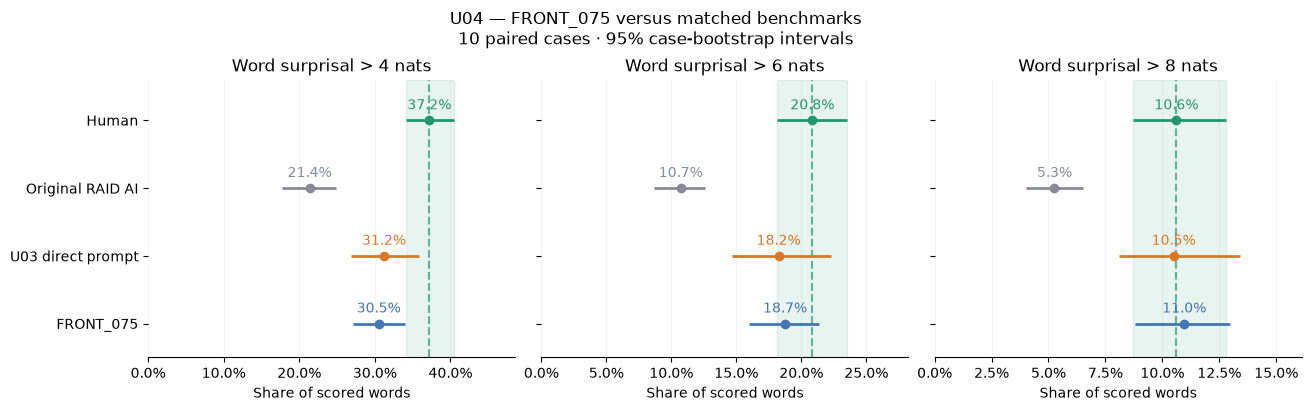

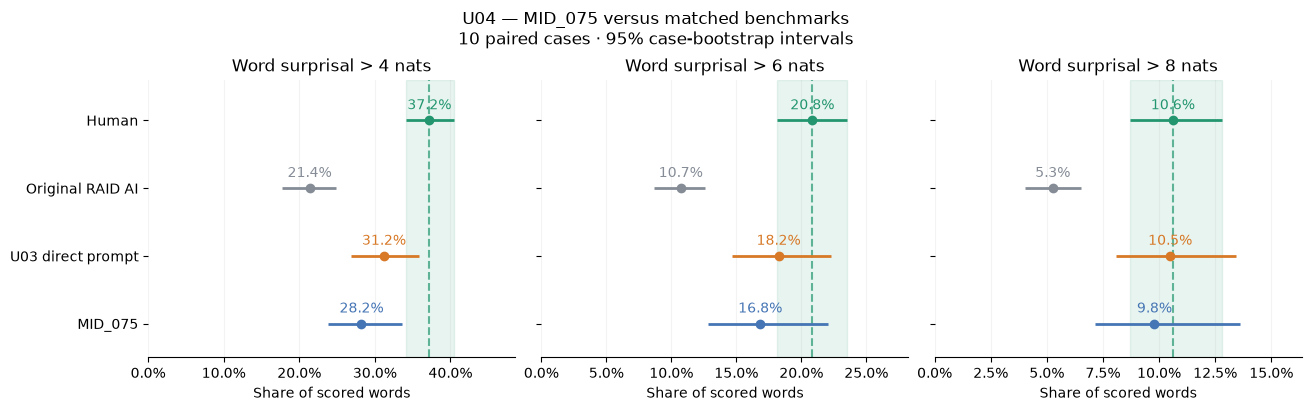

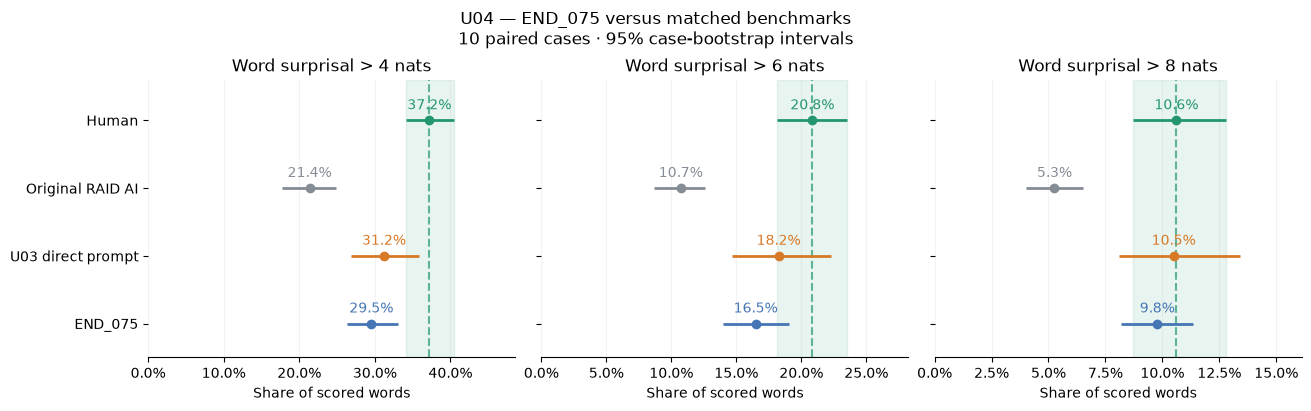

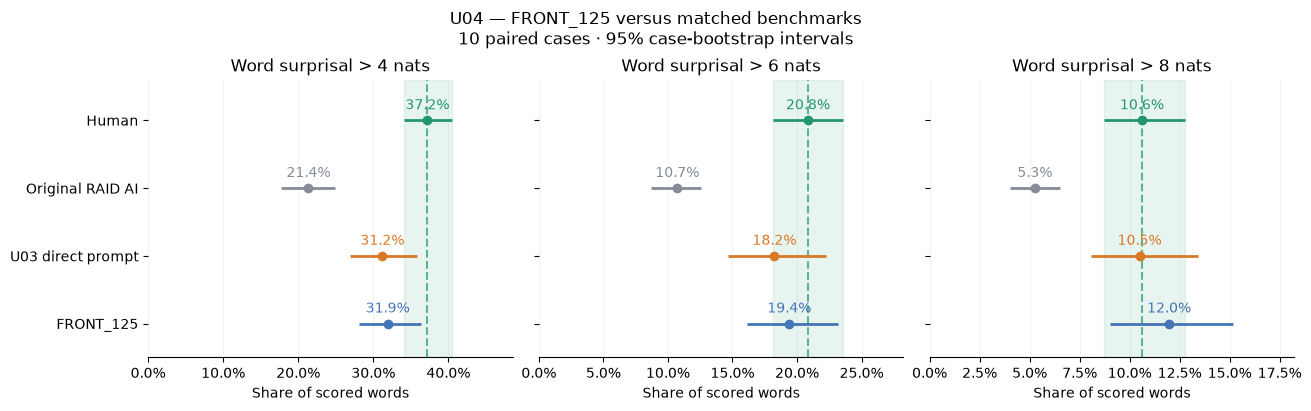

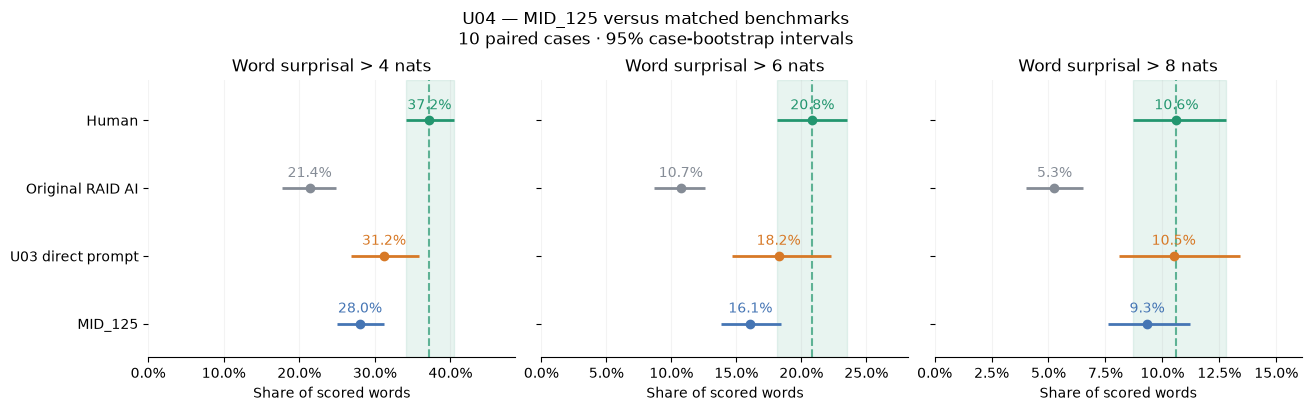

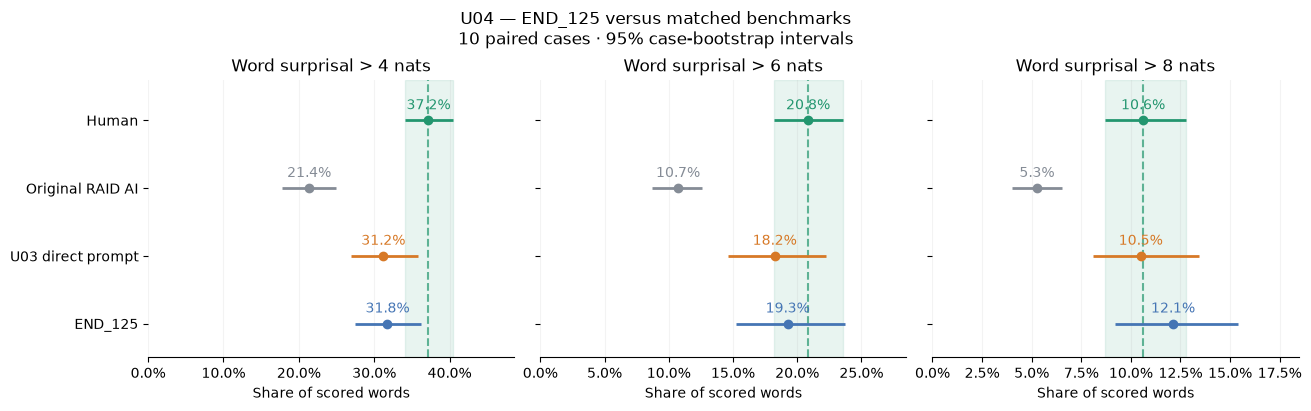

,arm,metric,cases,mean_delta_pp,ci_low_pp,ci_high_pp,increased,decreased,unchanged
0,FRONT_075,P_S_gt_4,10,-0.701,-4.874,3.529,4,6,0
1,FRONT_075,P_S_gt_6,10,0.499,-2.763,3.727,6,4,0
2,FRONT_075,P_S_gt_8,10,0.465,-2.247,3.102,6,4,0
3,MID_075,P_S_gt_4,10,-2.967,-7.245,1.091,4,6,0
4,MID_075,P_S_gt_6,10,-1.411,-5.410,3.003,4,6,0
5,MID_075,P_S_gt_8,10,-0.700,-4.122,3.130,4,6,0
6,END_075,P_S_gt_4,10,-1.671,-5.610,2.023,5,4,1
7,END_075,P_S_gt_6,10,-1.762,-5.229,1.543,4,5,1
8,END_075,P_S_gt_8,10,-0.717,-3.088,1.630,5,5,0
9,FRONT_125,P_S_gt_4,10,0.705,-4.742,6.762,5,5,0


Saved figures: ../figures
All completed arms retain token-capped outputs. Intervals are case-level, not seed-level.


In [13]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

def compare_completed_arms():
    if u04_scores.empty: return
    figures = ROOT / "figures"
    figures.mkdir(exist_ok=True)
    current_figures = U04_OUT / "figures"
    current_figures.mkdir(exist_ok=True)
    paired_rows, mean_rows = [], []
    completed, statuses = rebuild_tables()
    display(statuses.groupby(["arm","status"]).size().unstack(fill_value=0))
    for arm in ARMS:
        selected = u04_scores.loc[u04_scores.arm.eq(arm)]
        if set(selected.case_id) != set(RUN_CASES) or len(selected)!=10:
            print(f"{arm}: {len(selected)}/10 scored; comparison waits for the full arm.")
            continue
        order = ["HUMAN","OG","DIRECT_PROMPT",arm]
        labels = ["Human","Original RAID AI","U03 direct prompt",arm]
        colors = ["#23966F","#858C96","#D77927","#4575B4"]
        panel = pd.concat([benchmark_scores,selected],ignore_index=True)
        arrays = []
        for metric in METRICS:
            wide = panel.pivot(index="case_id",columns="arm",values=metric).reindex(index=RUN_CASES,columns=order)
            assert wide.notna().all().all()
            arrays.append(wide.to_numpy())
        values = 100*np.stack(arrays,axis=2)
        rng = np.random.default_rng(20260920)
        indices = rng.integers(0,10,size=(10000,10))
        means = values.mean(axis=0)
        boots = values[indices].mean(axis=1)
        lower,upper = np.quantile(boots,[0.025,0.975],axis=0)
        for j,metric in enumerate(METRICS):
            delta = values[:,3,j]-values[:,2,j]
            boot_delta = boots[:,3,j]-boots[:,2,j]
            lo,hi = np.quantile(boot_delta,[0.025,0.975])
            paired_rows.append(dict(arm=arm,metric=metric,cases=10,mean_delta_pp=delta.mean(),
                ci_low_pp=lo,ci_high_pp=hi,increased=int((delta>0).sum()),
                decreased=int((delta<0).sum()),unchanged=int((delta==0).sum())))
            for k,group in enumerate(order):
                mean_rows.append(dict(comparison_arm=arm,group=group,metric=metric,
                                      mean_percent=means[k,j],ci_low_percent=lower[k,j],ci_high_percent=upper[k,j]))
        with plt.rc_context({"font.size":10,"axes.spines.top":False,"axes.spines.right":False,
                             "axes.spines.left":False,"pdf.fonttype":42}):
            fig,axes = plt.subplots(1,3,figsize=(13,4),sharey=True,layout="constrained")
            for j,(ax,threshold) in enumerate(zip(axes,(4,6,8))):
                ax.axvspan(lower[0,j],upper[0,j],color=colors[0],alpha=.1)
                ax.axvline(means[0,j],color=colors[0],linestyle="--",alpha=.7)
                for k,color in enumerate(colors):
                    ax.hlines(k,lower[k,j],upper[k,j],color=color,lw=2)
                    ax.plot(means[k,j],k,"o",color=color)
                    ax.annotate(f"{means[k,j]:.1f}%",(means[k,j],k),xytext=(0,8),
                                textcoords="offset points",ha="center",color=color)
                ax.set_title(f"Word surprisal > {threshold} nats")
                ax.set_yticks(range(4),labels);ax.set_ylim(3.5,-.6)
                ax.set_xlim(0,float(upper[:,j].max())*1.2)
                ax.xaxis.set_major_formatter(PercentFormatter(100))
                ax.set_xlabel("Share of scored words");ax.grid(axis="x",alpha=.15)
            fig.suptitle(f"U04 — {arm} versus matched benchmarks\n10 paired cases · 95% case-bootstrap intervals")
            for directory in (figures,current_figures):
                fig.savefig(directory/f"U04_{arm}_vs_U03_OG_HUMAN.pdf",bbox_inches="tight")
                fig.savefig(directory/f"U04_{arm}_vs_U03_OG_HUMAN.png",dpi=240,bbox_inches="tight")
            plt.show();plt.close(fig)
    pd.DataFrame(mean_rows).to_csv(U04_OUT/"arm_means_percent.csv",index=False)
    paired_deltas = pd.DataFrame(paired_rows)
    paired_deltas.to_csv(U04_OUT/"paired_vs_U03_DP.csv",index=False)
    display(paired_deltas.round(3))
    print("Saved figures:",figures)
    print("All completed arms retain token-capped outputs. Intervals are case-level, not seed-level.")

compare_completed_arms()

## 7. Optional text audit — saved text only

In [14]:
AUDIT_CASE = RUN_CASES[0]
AUDIT_ARM = "FRONT_075"
source = run_cohort.loc[run_cohort.case_id.eq(AUDIT_CASE)].iloc[0]
print("ORIGINAL RAID AI\n", source.previous_ai)
print("\nU03 DIRECT PROMPT\n", benchmark_texts[AUDIT_CASE]["DIRECT_PROMPT"])
saved = read_completed(result_path(AUDIT_CASE,AUDIT_ARM),run_spec(source,AUDIT_ARM))
print("\nU04",AUDIT_ARM,"\n",saved["generated_text"] if saved else "Not completed yet.")

ORIGINAL RAID AI
 In this paper, we present a novel uncertainty-aware self-ensembling (UA-SE) model for semi-supervised learning of 3D left atrium segmentation. The UA-SE model exploits the correlations between neighboring voxels and uses a self-ensemble strategy to enhance the representation power of semi-supervised learning. We employ a 3D residual UNet with an uncertainty estimation module to model the spatial correlations and output the uncertainty map. Furthermore, we propose a self-ensembling module that can model both the label and uncertainty simultaneously by considering the local graph structure. The proposed model is trained in a semi-supervised manner, where only a small portion of the labeled data is used for training, and the remaining unlabeled data are utilized to enhance the model's representation power. We evaluate the proposed method on the publicly available MICCAI 3D Slicer Tracking Challenge 2017 dataset. The experimental results demonstrate the effectiveness of t

In [2]:
# U04 extension: remaining 10 cases × FRONT_075 / MID_075.
# Prerequisite: Section 0 of U04_context_range_sweep.ipynb.

import json
from pathlib import Path

assert "model" in globals() and "cohort" in globals(), (
    "Run Section 0 of the U04 generation notebook first."
)

extension_notebook = (
    ROOT / "experiments" / "U04_context_range_sweep.ipynb"
)
nb = json.loads(extension_notebook.read_text())

def source_with(marker):
    matches = [
        "".join(c["source"])
        for c in nb["cells"]
        if c["cell_type"] == "code"
        and marker in "".join(c["source"])
    ]
    assert len(matches) == 1, f"Expected one source cell: {marker}"
    return matches[0]

def replace_once(source, old, new):
    assert source.count(old) == 1, f"Unexpected notebook version: {old}"
    return source.replace(old, new, 1)

# Preserve the original notebook and its first-10 checkpoint contract.
setup = source_with('U04_NAMESPACE = "U04_context_range_sweep_v1"')
setup = replace_once(
    setup,
    'U04_NAMESPACE = "U04_context_range_sweep_v1"',
    'U04_NAMESPACE = "U04_context_range_remaining10_F75_M75_v1"',
)
setup = replace_once(
    setup,
    "cohort.case_id.astype(str).head(10).tolist()",
    "cohort.case_id.astype(str).iloc[10:20].tolist()",
)

start = setup.index("ARMS = {")
end = setup.index("\nMETRICS =", start)
setup = setup[:start] + """ARMS = {
    "FRONT_075": (0.75, 1.0, 1.0),
    "MID_075":   (1.0, 0.75, 1.0),
}
""" + setup[end:]

# Retain the end-band boundary test without requiring an END arm.
backend = source_with("def history_bias(")
backend = replace_once(
    backend, 'ARMS["END_125"]', "(1.0, 1.0, 1.25)"
)
backend = backend.replace("all six arm effects", "both arm effects")
checkpoint_controller = source_with("def run_spec(row, arm):")

assert len(cohort) == 20
assert cohort.case_id.astype(str).nunique() == 20

# Compile everything before executing setup or starting generation.
extension_cells = [
    compile(src, f"<U04 extension {name}>", "exec")
    for name, src in [
        ("setup", setup),
        ("preflight", backend),
        ("controller", checkpoint_controller),
    ]
]
for compiled in extension_cells:
    exec(compiled, globals())

assert RUN_CASES == cohort.case_id.astype(str).iloc[10:20].tolist()
assert set(ARMS) == {"FRONT_075", "MID_075"}

print("Remaining cases:", RUN_CASES, flush=True)
print("Checkpoint directory:", U04_OUT, flush=True)

for arm in ("FRONT_075", "MID_075"):
    completed = run_arm(arm)

completed, batch_status = rebuild_tables()
display(
    batch_status.groupby(["arm", "status"])
    .size().unstack(fill_value=0)
)
print(f"Saved {len(completed)}/20 extension rewrites.")

,front_<64,mid_64_to_128,end_>128
FRONT_075,0.75,1.00,1.0
MID_075,1.00,0.75,1.0


,case_id,domain
0,gate_0062,reddit
1,gate_0078,wiki
2,gate_0079,abstracts
3,gate_0075,books
4,gate_0024,news
5,gate_0018,recipes
6,gate_0050,reddit
7,gate_0051,wiki
8,gate_0046,abstracts
9,gate_0016,books


Output: ../results/causal/U04_context_range_remaining10_F75_M75_v1 | planned rewrites: 20
Benchmarks: 30 saved scores for these exact 10 cases. No rewrite started.
Neutral custom-mask vs native TV: 0.0


,arm,preflight_TV_from_neutral
0,FRONT_075,0.020502
1,MID_075,0.006053


Mask boundaries and both arm effects verified. No rewrite started.
Remaining cases: ['gate_0062', 'gate_0078', 'gate_0079', 'gate_0075', 'gate_0024', 'gate_0018', 'gate_0050', 'gate_0051', 'gate_0046', 'gate_0016']
Checkpoint directory: ../results/causal/U04_context_range_remaining10_F75_M75_v1
FRONT_075: 0/10 already saved; starting/resuming.
[1/10] FRONT_075 | gate_0062
  FRONT_075 / gate_0062: evaluating prefix 85 tokens | 203 forwards | 0.5 min
  FRONT_075 / gate_0062: evaluating prefix 157 tokens | 368 forwards | 1.0 min
  FRONT_075 / gate_0062: evaluating prefix 230 tokens | 511 forwards | 1.5 min
  FRONT_075 / gate_0062: evaluating prefix 288 tokens | 645 forwards | 2.0 min
  SAVED eos | 343 tokens | 0 rewinds
[2/10] FRONT_075 | gate_0078
  FRONT_075 / gate_0078: evaluating prefix 154 tokens | 170 forwards | 0.5 min
  FRONT_075 / gate_0078: evaluating prefix 278 tokens | 305 forwards | 1.0 min
  FRONT_075 / gate_0078: evaluating prefix 395 tokens | 422 forwards | 1.5 min
  FRONT

...

FRONT_075: 10/10 saved. Next arm runs only when you execute its cell.
MID_075: 0/10 already saved; starting/resuming.
[1/10] MID_075 | gate_0062
  MID_075 / gate_0062: evaluating prefix 81 tokens | 204 forwards | 0.5 min
  MID_075 / gate_0062: evaluating prefix 145 tokens | 371 forwards | 1.0 min
  MID_075 / gate_0062: evaluating prefix 198 tokens | 528 forwards | 1.5 min
  MID_075 / gate_0062: evaluating prefix 281 tokens | 670 forwards | 2.0 min
  MID_075 / gate_0062: evaluating prefix 372 tokens | 797 forwards | 2.5 min
  SAVED eos | 403 tokens | 0 rewinds
[2/10] MID_075 | gate_0078
  MID_075 / gate_0078: evaluating prefix 142 tokens | 172 forwards | 0.5 min
  MID_075 / gate_0078: evaluating prefix 218 tokens | 317 forwards | 1.0 min
  MID_075 / gate_0078: evaluating prefix 304 tokens | 447 forwards | 1.5 min
  MID_075 / gate_0078: evaluating prefix 395 tokens | 562 forwards | 2.0 min
  MID_075 / gate_0078: evaluating prefix 499 tokens | 666 forwards | 2.5 min
  MID_075 / gate_0078:

,case_id,domain,arm,stop_reason,word_count,coherence_rewinds,elapsed_seconds
10,gate_0062,reddit,MID_075,eos,331,0,160.468088
11,gate_0078,wiki,MID_075,truncated,499,2,218.969010
12,gate_0079,abstracts,MID_075,eos,350,6,355.429373
13,gate_0075,books,MID_075,truncated,481,0,306.214859
14,gate_0024,news,MID_075,eos,343,0,127.161432
15,gate_0018,recipes,MID_075,truncated,206,0,227.985017
16,gate_0050,reddit,MID_075,eos,313,0,239.952535
17,gate_0051,wiki,MID_075,truncated,466,0,196.053039
18,gate_0046,abstracts,MID_075,eos,249,2,149.324941
19,gate_0016,books,MID_075,eos,473,4,327.846423


MID_075: 10/10 saved. Next arm runs only when you execute its cell.


status,eos,truncated
arm,,
FRONT_075,9,1
MID_075,6,4


Saved 20/20 extension rewrites.


In [3]:
# Remaining 34 fixed-cohort cases using the accepted M75 pipeline.
# Prerequisite: Section 0 of U04_context_range_sweep.ipynb.
# Shut down the Qwen evaluation kernel first to free GPU memory.

import json
from pathlib import Path
import pandas as pd

assert all(name in globals() for name in (
    "ROOT", "model", "case_contract", "build_messages"
)), "Run Section 0 of the U04 generation notebook first."

# Recover the original fixed-54 task prompts.
fixed54 = pd.read_parquet(
    ROOT / "results/causal/U00_soft_history_bruteforce/fixed54_prompts.parquet"
)
original20 = pd.read_csv(
    ROOT / "results/causal/U01_temporal_method_selection/cohort20.csv",
    keep_default_na=False,
)
fixed54["case_id"] = fixed54.case_id.astype(str)
original20["case_id"] = original20.case_id.astype(str)

assert len(fixed54) == 54 and fixed54.case_id.is_unique
assert len(original20) == 20 and original20.case_id.is_unique
assert set(original20.case_id).issubset(set(fixed54.case_id))
assert {"case_id", "source_id", "domain", "prompt"} <= set(fixed54.columns)

# Verify that these are the same prompts/source IDs used in the first 20.
fixed_lookup = fixed54.set_index("case_id")
for row in original20.itertuples(index=False):
    reference = fixed_lookup.loc[row.case_id]
    assert str(reference.source_id) == str(row.source_id), row.case_id
    assert str(reference.prompt) == str(row.prompt), row.case_id

remaining34 = fixed54.loc[
    ~fixed54.case_id.isin(original20.case_id),
    ["case_id", "source_id", "domain", "prompt"],
].copy()
assert len(remaining34) == 34
assert set(remaining34.case_id).issubset(case_contract)

# WITH_PREV comes strictly from the original AI corpus rows.
ai_corpus34 = pd.read_parquet(
    ROOT / "results/causal/C02d2_fz118_ghostbuster_raid/paired_corpus.parquet"
)
ai_corpus34 = ai_corpus34.loc[ai_corpus34.label.eq(1)].copy()
previous34 = []
for row in remaining34.itertuples(index=False):
    match = ai_corpus34.loc[
        ai_corpus34.source_id.astype(str).eq(str(row.source_id))
    ]
    assert len(match) == 1, f"{row.case_id}: ambiguous/missing original AI."
    assert str(match.iloc[0].domain) == str(row.domain)
    text = match.iloc[0].text
    assert isinstance(text, str) and text.strip(), row.case_id
    assert isinstance(row.prompt, str) and row.prompt.strip(), row.case_id
    previous34.append(text)
remaining34["previous_ai"] = previous34

# Load existing generation definitions without executing old experiments.
notebook34 = ROOT / "experiments/U04_context_range_sweep.ipynb"
nb34 = json.loads(notebook34.read_text())

def source34(marker):
    import ast

    matches = []
    for cell in nb34["cells"]:
        if cell["cell_type"] != "code":
            continue

        source = "".join(cell["source"])
        try:
            nodes = ast.parse(source).body
        except SyntaxError:
            continue

        if marker.startswith("U04_NAMESPACE"):
            found = any(
                isinstance(node, ast.Assign)
                and any(
                    isinstance(target, ast.Name)
                    and target.id == "U04_NAMESPACE"
                    for target in node.targets
                )
                and isinstance(node.value, ast.Constant)
                and node.value.value == "U04_context_range_sweep_v1"
                for node in nodes
            )
        else:
            function_name = marker.split("def ", 1)[1].split("(", 1)[0]
            found = any(
                isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
                and node.name == function_name
                for node in nodes
            )

        if found:
            matches.append(source)

    # Identical copies of a definition cell are harmless.
    matches = list(dict.fromkeys(matches))
    assert len(matches) == 1, (
        f"Expected one definition cell for {marker}; found {len(matches)}."
    )
    return matches[0]

def replace34(source, old, new):
    assert source.count(old) == 1, f"Unexpected notebook version: {old}"
    return source.replace(old, new, 1)

setup34 = source34('U04_NAMESPACE = "U04_context_range_sweep_v1"')
setup34 = replace34(
    setup34,
    'U04_NAMESPACE = "U04_context_range_sweep_v1"',
    'U04_NAMESPACE = "U04_M75_remaining34_v1"',
)
setup34 = replace34(
    setup34,
    'RUN_CASES = cohort.case_id.astype(str).head(10).tolist()',
    'RUN_CASES = remaining34.case_id.tolist()',
)
setup34 = replace34(
    setup34,
    'assert len(RUN_CASES) == len(set(RUN_CASES)) == 10',
    'assert len(RUN_CASES) == len(set(RUN_CASES)) == 34',
)
setup34 = replace34(
    setup34,
    'run_cohort = cohort.set_index("case_id").loc[RUN_CASES].reset_index()',
    'run_cohort = remaining34.copy()',
)

start34 = setup34.index("ARMS = {")
end34 = setup34.index("\nMETRICS =", start34)
setup34 = (
    setup34[:start34]
    + 'ARMS = {"MID_075": (1.0, 0.75, 1.0)}\n'
    + setup34[end34:]
)

# These new cases have no U03 DP results; generation does not need benchmarks.
start34 = setup34.index('score_path = U03_COMPARE / "five_group_scores.csv"')
end34 = setup34.index("assert SELF_NB.exists()", start34)
setup34 = (
    setup34[:start34]
    + """benchmark_provenance = []
benchmark_scores = pd.DataFrame(columns=["case_id", "arm"])
"""
    + setup34[end34:]
)
setup34 = setup34.replace(
    'print("Benchmarks: 30 saved scores for these exact 10 cases. No rewrite started.")',
    'print("Remaining 34 selected. No rewrite started.")',
)

backend34 = source34("def history_bias(")
backend34 = replace34(
    backend34, 'ARMS["END_125"]', "(1.0, 1.0, 1.25)"
)
backend34 = backend34.replace("all six arm effects", "M75 effect")

controller34 = source34("def run_spec(row, arm):")
controller34 = controller34.replace("/10", "/34")

compiled34 = [
    compile(source, f"<M75 remaining34: {label}>", "exec")
    for label, source in [
        ("setup", setup34),
        ("preflight", backend34),
        ("controller", controller34),
    ]
]

# Setup freezes model/settings/input hashes; preflight checks attention behavior.
for code34 in compiled34:
    exec(code34, globals())

assert ARMS == {"MID_075": (1.0, 0.75, 1.0)}
assert FS_MAX_REWINDS == 10
assert len(run_cohort) == 34
assert not set(RUN_CASES) & set(original20.case_id)

# Record this extension's exact implementation for reproducibility.
extension34 = {
    "setup_sha": sha_text(setup34),
    "backend_sha": sha_text(backend34),
    "controller_sha": sha_text(controller34),
    "excluded_original20": original20.case_id.tolist(),
}
with generation_lock():
    extension_path34 = U04_OUT / "extension_implementation.json"
    if extension_path34.exists():
        assert json.loads(extension_path34.read_text()) == extension34
    else:
        atomic_json(extension_path34, extension34)

print("Output:", U04_OUT, flush=True)
display(run_cohort[["case_id", "domain"]])

# Atomic per-case checkpoints; reruns reuse completed EOS/token-capped outputs.
completed34 = run_arm("MID_075")

completed34, status34 = rebuild_tables()
display(status34.groupby(["arm", "status"]).size().unstack(fill_value=0))
print(f"Saved {len(completed34)}/34 new M75 rewrites.")
print("Together with the previous 20: 54 M75 cases when this batch completes.")

,front_<64,mid_64_to_128,end_>128
MID_075,1.0,0.75,1.0


,case_id,domain
0,gate_0001,abstracts
2,gate_0004,recipes
3,gate_0005,reddit
4,gate_0007,wiki
5,gate_0015,abstracts
9,gate_0019,reddit
10,gate_0020,reviews
11,gate_0021,wiki
12,gate_0022,abstracts
13,gate_0023,books


Output: ../results/causal/U04_M75_remaining34_v1 | planned rewrites: 34
Remaining 34 selected. No rewrite started.
Neutral custom-mask vs native TV: 0.0


,arm,preflight_TV_from_neutral
0,MID_075,0.000005


Mask boundaries and M75 effect verified. No rewrite started.
Output: ../results/causal/U04_M75_remaining34_v1


...

MID_075: 0/34 already saved; starting/resuming.
[1/34] MID_075 | gate_0001
  MID_075 / gate_0001: evaluating prefix 45 tokens | 241 forwards | 0.5 min
  MID_075 / gate_0001: evaluating prefix 68 tokens | 474 forwards | 1.0 min
  MID_075 / gate_0001: evaluating prefix 238 tokens | 664 forwards | 1.5 min
  MID_075 / gate_0001: evaluating prefix 383 tokens | 809 forwards | 2.0 min
  SAVED eos | 436 tokens | 0 rewinds
[2/34] MID_075 | gate_0004
  MID_075 / gate_0004: evaluating prefix 106 tokens | 166 forwards | 0.5 min
  MID_075 / gate_0004: evaluating prefix 178 tokens | 308 forwards | 1.0 min
  MID_075 / gate_0004: evaluating prefix 197 tokens | 442 forwards | 1.5 min
  MID_075 / gate_0004: evaluating prefix 271 tokens | 571 forwards | 2.0 min
  MID_075 / gate_0004: evaluating prefix 326 tokens | 681 forwards | 2.5 min
  MID_075 / gate_0004: evaluating prefix 348 tokens | 786 forwards | 3.0 min
  MID_075 / gate_0004: evaluating prefix 367 tokens | 886 forwards | 3.5 min
  MID_075 / gate

,case_id,domain,arm,stop_reason,word_count,coherence_rewinds,elapsed_seconds
0,gate_0001,abstracts,MID_075,eos,363,0,132.255596
1,gate_0004,recipes,MID_075,truncated,400,0,556.633345
2,gate_0005,reddit,MID_075,eos,171,0,48.528208
3,gate_0007,wiki,MID_075,truncated,443,0,212.127037
4,gate_0015,abstracts,MID_075,eos,416,3,161.857069
5,gate_0019,reddit,MID_075,eos,340,0,133.758749
6,gate_0020,reviews,MID_075,truncated,491,0,240.046675
7,gate_0021,wiki,MID_075,eos,424,0,187.504496
8,gate_0022,abstracts,MID_075,eos,262,3,175.855281
9,gate_0023,books,MID_075,truncated,470,0,475.857843


MID_075: 10/34 saved. Next arm runs only when you execute its cell.


status,eos,truncated
arm,,
MID_075,25,9


Saved 34/34 new M75 rewrites.
Together with the previous 20: 54 M75 cases when this batch completes.
